# 06 · Remediation: PD recalibration

The validation in notebook 05 found that the models **rank** borrowers well on 2017 but
**under-predict the PD level**:

| Finding | Severity | Issue |
|---|---|---|
| F2 | High | Scorecard: observed / predicted 1.19 on OOT |
| F3 | Medium | Boosting: observed / predicted 1.05 on OOT |
| F4 | Medium | Calibration differs between loans issued before and in 2016 (2016 bureau fields) |

This notebook does what a developer would do in response, then re-tests on OOT.

**The rule that keeps the test honest.** Recalibration parameters are fitted only on data
a bank would have had at deployment: the **most recent matured cohort of the development
sample**, test loans issued in **2016** (the models were not fitted on them). The 2017 OOT
loans are used only to check the result.

**Why recalibration is enough here.** Recalibration is a monotone transform of each model's
log-odds, so the ranking, and therefore Gini, does not change. It fixes the PD level, which
is what F2–F4 are about. F1 (the scorecard ranks worse than the benchmark) cannot be fixed by
recalibration and stays open.

In [1]:
import sys
import pickle
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import TARGET
from src.features_config import CATEGORICAL
from src.split import PROCESSED_PATH
from src.scoring import Models
from src.calibration import InterceptShift, LogisticRecalibration
from src.metrics import gini, calibration_table, hosmer_lemeshow

FIG = ROOT / "reports" / "figures"
TABLES = ROOT / "reports" / "tables"
MODELS_DIR = ROOT / "models"
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50, "display.width", 160)

def save(fig, name):
    fig.savefig(FIG / f"06_{name}.png", dpi=120, bbox_inches="tight")

CANDIDATES = ["Scorecard", "LightGBM monotone", "CatBoost monotone"]

## 1. Score the calibration and evaluation samples

In [2]:
samples = pd.read_parquet(PROCESSED_PATH)
test = samples[samples["sample"] == "test"]
oot = samples[samples["sample"] == "oot"]
sets = {
    "calibration: test 2016": test[test["issue_d"] >= "2016-01-01"],
    "test 2013-2015": test[test["issue_d"] < "2016-01-01"],
    "OOT 2017": oot,
}
models = Models({c: sorted(samples[c].dropna().astype(str).unique()) for c in CATEGORICAL})
PD = {k: models.predict(d) for k, d in sets.items()}
Y = {k: d[TARGET].to_numpy() for k, d in sets.items()}
pd.DataFrame({k: {"loans": len(d), "default_rate": d[TARGET].mean()} for k, d in sets.items()}).T.round(4)

,loans,default_rate
calibration: test 2016,63518.0,0.0443
test 2013-2015,101098.0,0.0323
OOT 2017,296484.0,0.0404


## 2. Before recalibration

In [3]:
before = pd.DataFrame({name: {k: Y[k].mean() / PD[k][name].mean() for k in sets} for name in CANDIDATES}).T
before.columns = [f"obs/pred, {c}" for c in before.columns]
before.round(3)

,"obs/pred, calibration: test 2016","obs/pred, test 2013-2015","obs/pred, OOT 2017"
Scorecard,1.166,0.892,1.189
LightGBM monotone,1.015,0.996,1.051
CatBoost monotone,0.977,0.938,0.992


The pattern behind F4 is visible: every model is close to calibrated on 2013–2015 loans and
under-predicts on 2016, the regime in which all 2016 bureau fields are filled, as they are in
2017. That is why the calibration sample has to be the 2016 cohort and not the whole test
sample.

## 3. Fit the recalibration on test 2016

Two methods, both fitted on the calibration sample only:

* **intercept shift**: moves every PD by the same amount on the log-odds scale;
* **logistic (Platt)**: logit(PD′) = a + b · logit(PD); b ≠ 1 means the original PDs
  were too steep (b < 1) or too flat (b > 1).

As a counter-example, an intercept shift fitted on the **whole** test sample (2013–2016)
shows what happens if the regime change is ignored.

In [4]:
cal_key = "calibration: test 2016"
whole_test = test
pd_whole = models.predict(whole_test)

calibrators, params = {}, []
for name in CANDIDATES:
    calibrators[(name, "intercept shift")] = InterceptShift().fit(PD[cal_key][name], Y[cal_key])
    calibrators[(name, "logistic")] = LogisticRecalibration().fit(PD[cal_key][name], Y[cal_key])
    calibrators[(name, "intercept shift, whole test (counter-example)")] = InterceptShift().fit(
        pd_whole[name], whole_test[TARGET].to_numpy())
    params.append({"model": name,
                   "shift (2016)": calibrators[(name, "intercept shift")].shift_,
                   "logistic a": calibrators[(name, "logistic")].a_,
                   "logistic b": calibrators[(name, "logistic")].b_,
                   "shift (whole test)": calibrators[(name, "intercept shift, whole test (counter-example)")].shift_})
pd.DataFrame(params).set_index("model").round(4)

,shift (2016),logistic a,logistic b,shift (whole test)
model,,,,
Scorecard,0.1640,-0.1738,0.8890,0.0010
LightGBM monotone,0.0157,-0.1438,0.9432,0.0050
CatBoost monotone,-0.0254,0.0997,1.0446,-0.0482


## 4. Re-test on OOT 2017

In [5]:
y = Y["OOT 2017"]
rows = []
for name in CANDIDATES:
    variants = {"original": PD["OOT 2017"][name]}
    for method in ["intercept shift", "logistic", "intercept shift, whole test (counter-example)"]:
        variants[method] = calibrators[(name, method)].transform(PD["OOT 2017"][name])
    for method, p in variants.items():
        ct = calibration_table(y, p)
        hl, hl_p = hosmer_lemeshow(y, p)
        rows.append({"model": name, "method": method, "gini": gini(y, p), "mean_pd": p.mean(),
                     "default_rate": y.mean(), "obs_to_pred": y.mean() / p.mean(),
                     "deciles_failing_binomial": int((ct["binomial_p"] < 0.05).sum()),
                     "hosmer_lemeshow": hl, "hl_p_value": hl_p})
after = pd.DataFrame(rows).set_index(["model", "method"])
after.round(4)

gini  mean_pd  default_rate  obs_to_pred  deciles_failing_binomial  hosmer_lemeshow  \
model             method                                                                                                                                 
Scorecard         original                                       0.3396   0.0340        0.0404       1.1887                         8         493.9045   
                  intercept shift                                0.3396   0.0397        0.0404       1.0181                         6         102.5616   
                  logistic                                       0.3396   0.0402        0.0404       1.0053                         4          39.8222   
                  intercept shift, whole test (counter-example)  0.3396   0.0340        0.0404       1.1876                         8         489.5241   
LightGBM monotone original                                       0.4298   0.0385        0.0404       1.0506                         4          57.2074   
                  intercept shift                                0.4298   0.0390        0.0404       1.0353                         3          40.9641   
                  logistic                                       0.4298   0.0393        0.0404       1.0279                         5          39.7334   
                  intercept shift, whole test (counter-example)  0.4298   0.0386        0.0404       1.0458                         3          51.5043   
CatBoost monotone original                                       0.4255   0.0407        0.0404       0.9924                         6          88.3428   
                  intercept shift                                0.4255   0.0397        0.0404       1.0164                         7          92.9515   
                  logistic                                       0.4255   0.0395        0.0404       1.0215                         4          57.8677   
                  intercept shift, whole test (counter-example)  0.4255   0.0389        0.0404       1.0383                         7         109.3389   

                                                                 hl_p_value  
model             method                                                     
Scorecard         original                                              0.0  
                  intercept shift                                       0.0  
                  logistic                                              0.0  
                  intercept shift, whole test (counter-example)         0.0  
LightGBM monotone original                                              0.0  
                  intercept shift                                       0.0  
                  logistic                                              0.0  
                  intercept shift, whole test (counter-example)         0.0  
CatBoost monotone original                                              0.0  
                  intercept shift                                       0.0  
                  logistic                                              0.0  
                  intercept shift, whole test (counter-example)         0.0

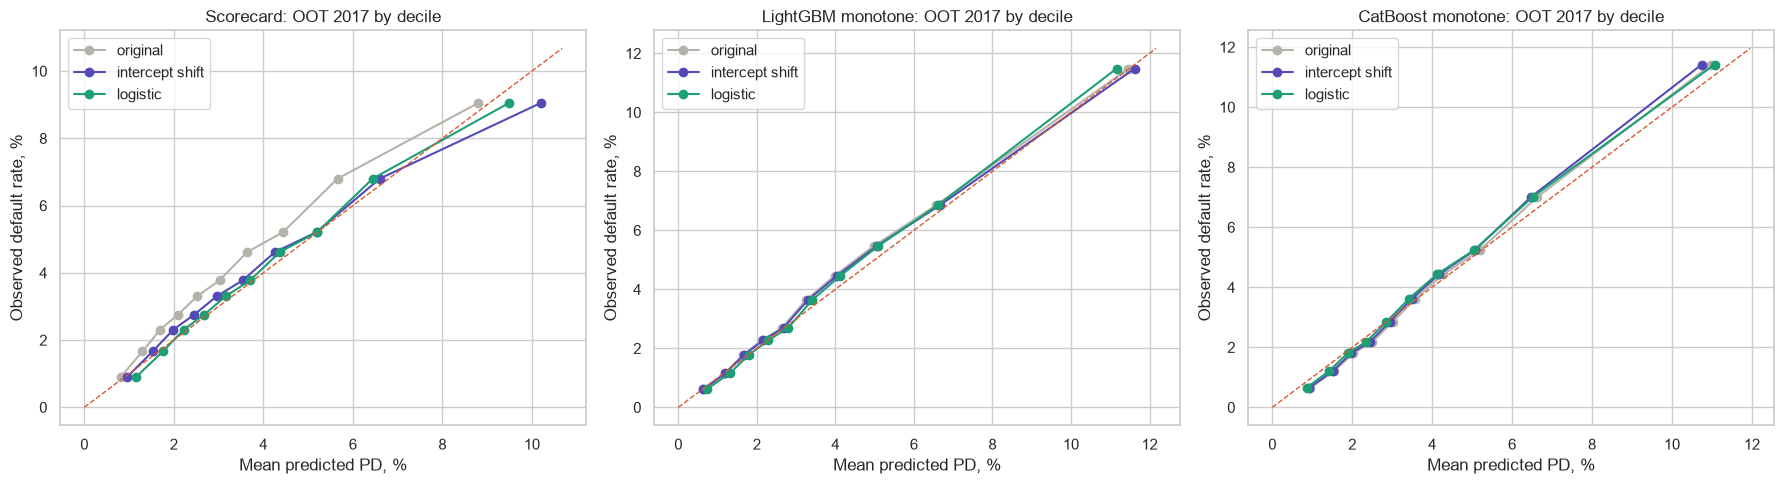

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
styles = [("original", "#B4B2A9"), ("intercept shift", "#534AB7"), ("logistic", "#1D9E75")]
for ax, name in zip(axes, CANDIDATES):
    for method, color in styles:
        p = PD["OOT 2017"][name] if method == "original" else calibrators[(name, method)].transform(PD["OOT 2017"][name])
        ct = calibration_table(y, p)
        ax.plot(ct["mean_pd"] * 100, ct["default_rate"] * 100, "o-", color=color, label=method)
    lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.plot([0, lim], [0, lim], ls="--", color="#D85A30", lw=1)
    ax.set_title(f"{name}: OOT 2017 by decile")
    ax.set_xlabel("Mean predicted PD, %")
    ax.set_ylabel("Observed default rate, %")
    ax.legend()
fig.tight_layout()
save(fig, "recalibration")
plt.show()

## 5. Save

The fitted calibrators go to `models/recalibration.pkl`; the re-test results to
`reports/tables/06_recalibration.csv`.

In [7]:
after.round(5).to_csv(TABLES / "06_recalibration.csv")
with open(MODELS_DIR / "recalibration.pkl", "wb") as fh:
    pickle.dump({k: v for k, v in calibrators.items() if "counter-example" not in k[1]}, fh)
print("saved")

saved


## 6. Conclusions

### Result on OOT 2017 (Gini unchanged by construction)
| Model | Method chosen | Observed / predicted before → after | Deciles failing binomial test | Hosmer–Lemeshow |
|---|---|---|---|---|
| Scorecard | logistic (a = −0.17, b = 0.89) | 1.19 → **1.01** | 8 → 4 | 494 → 40 |
| LightGBM monotone | intercept shift (+0.016) | 1.05 → **1.04** | 4 → 3 | 57 → 41 |
| CatBoost monotone | logistic (a = 0.10, b = 1.04) | 0.99 → 1.02 | 6 → 4 | 88 → 58 |

- **The scorecard's under-prediction is fixed.** Its mean PD moves from 3.40% to 4.02%
  against an observed 4.04%. The fitted slope b = 0.89 < 1 also shows its original PDs were
  slightly too steep, which the logistic method corrects.
- **LightGBM barely needs recalibration:** on the 2016 cohort it was already close to
  calibrated (1.015). The remaining 3–4% gap on OOT comes from 2017 itself and could not
  have been seen at deployment time; it sits inside the green monitoring band (0.9–1.1).
- **CatBoost monotone was already the best calibrated** on level; recalibration improves the
  shape across deciles (failing deciles 6 → 4) at the cost of a slight over-shift in level.
- **The counter-example proves the point of F4.** An intercept shift fitted on the whole test
  sample (2013–2016) is almost zero and leaves the scorecard at 1.19: the under-prediction
  comes from the 2016 regime, so only a calibration on the most recent cohort fixes it.
- Hosmer–Lemeshow still rejects every model. With 296,484 loans the test detects deviations
  far too small to matter in practice; the observed / predicted ratio and the size of the
  decile deviations are the relevant measures at this sample size.

### Status of the findings
| ID | Severity | Status after remediation |
|---|---|---|
| F1 | High | **Open.** Recalibration does not change ranking; the scorecard stays below the benchmark. |
| F2 | High | **Remediated.** Scorecard observed / predicted 1.01 on OOT. |
| F3 | Medium | **Remediated within tolerance.** Boosting observed / predicted 1.02–1.04, inside 0.9–1.1; keep a margin of conservatism and quarterly monitoring. |
| F4 | Medium | **Mitigated.** Calibrating on the 2016 cohort neutralises the effect; the root cause (training on periods with and without the 2016 fields) remains, so re-estimation on 2016+ data is still recommended. |
| F5–F9 | Medium / Low | Open, not affected by recalibration. |

The condition "recalibrate before PD use" for LightGBM monotone and CatBoost monotone is met.
Their verdict stays **approved with conditions**, with the remaining conditions on
`loan_amnt` documentation (F6) and the fair-lending analysis (F7).